<a href="https://colab.research.google.com/github/Guru1315/DAILY_PROJECTS_OF_ML-ALGORITHMS/blob/Linear_Regression/AI_Resume_Screening_System.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q pdfplumber python-docx sentence-transformers scikit-learn nltk pandas matplotlib seaborn

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.7/43.7 kB 1.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.4/62.4 kB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.0/60.0 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.6/6.6 MB 38.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 253.0/253.0 kB 13.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.1/7.1 MB 40.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.8/3.8 MB 59.2 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.29.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.


In [2]:
!pip install -q pdfplumber python-docx

In [3]:
!pip install "Pillow<=10.4.0" "pdfplumber<0.11.1" sentence-transformers -q

import os, re, io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pdfplumber
import docx
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sentence_transformers import SentenceTransformer

nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)
nltk.download('omw-1.4', quiet=True)
print(" Libraries ready")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.5/4.5 MB 29.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.4/56.4 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.6/5.6 MB 51.8 MB/s eta 0:00:00
 Libraries ready


In [4]:
job_title = "Machine Learning Engineer"

job_description = """
We are looking for a Machine Learning Engineer to design, train and deploy ML models.
Requirements: strong Python programming, experience with machine learning, deep learning,
NLP, TensorFlow or PyTorch, scikit-learn, pandas, numpy, SQL, data preprocessing,
model evaluation, and Git. Knowledge of Docker, AWS and REST APIs is a plus.
Good communication and teamwork skills are required.
"""

required_skills = [
    "python", "machine learning", "deep learning", "nlp", "tensorflow", "pytorch",
    "scikit-learn", "pandas", "numpy", "sql", "git", "docker", "aws", "rest api",
    "data preprocessing", "model evaluation", "communication", "teamwork"
]
print("Job:", job_title)

Job: Machine Learning Engineer


In [5]:
from google.colab import files
uploaded = files.upload()
print(f"\n {len(uploaded)} file(s) uploaded")

Saving Ananya_Iyer_Data_Analyst.pdf to Ananya_Iyer_Data_Analyst.pdf
Saving Arjun_Kumar_ML_Engineer.pdf to Arjun_Kumar_ML_Engineer.pdf
Saving Priya_Sharma_Data_Scientist.pdf to Priya_Sharma_Data_Scientist.pdf
Saving Rahul_Verma_Web_Developer.pdf to Rahul_Verma_Web_Developer.pdf
Saving Sneha_Reddy_AI_Student.pdf to Sneha_Reddy_AI_Student.pdf
Saving Vikram_Singh_Accountant.pdf to Vikram_Singh_Accountant.pdf

 6 file(s) uploaded


In [6]:
def extract_text(filename, file_bytes):
    ext = os.path.splitext(filename)[1].lower()
    text = ""
    try:
        if ext == ".pdf":
            with pdfplumber.open(io.BytesIO(file_bytes)) as pdf:
                text = "\n".join((p.extract_text() or "") for p in pdf.pages)
        elif ext == ".docx":
            d = docx.Document(io.BytesIO(file_bytes))
            text = "\n".join(p.text for p in d.paragraphs)
        elif ext == ".txt":
            text = file_bytes.decode("utf-8", errors="ignore")
        else:
            print(f" Unsupported file type skipped: {filename}")
    except Exception as e:
        print(f" Could not read {filename}: {e}")
    return text

resumes = {}
for name, data in uploaded.items():
    t = extract_text(name, data)
    if t.strip():
        resumes[name] = t

if not resumes:
    print("No valid uploads found → using SAMPLE resumes for demo.\n")
    resumes = {
      "Aarav_ML_Engineer.txt": "Machine learning engineer with 3 years experience in Python, TensorFlow, PyTorch, scikit-learn, pandas and numpy. Built NLP models for text classification, deep learning pipelines, model evaluation and data preprocessing. Deployed with Docker on AWS, used Git and REST APIs. Strong teamwork and communication.",
      "Diya_Data_Analyst.txt": "Data analyst skilled in SQL, Excel, Power BI and Tableau. Experience with pandas and numpy for data cleaning and reporting. Basic Python and statistics. Good communication skills.",
      "Karan_Web_Developer.txt": "Full stack web developer with HTML, CSS, JavaScript, React, Node.js and MongoDB. Built REST APIs and responsive websites. Familiar with Git and Docker.",
      "Meera_AI_Student.txt": "B.Tech AI student. Projects in Python, NLP sentiment analysis, scikit-learn and PyTorch. Completed deep learning and machine learning courses. Knows SQL, Git, pandas, numpy. Eager to learn and work in teams.",
      "Rohit_Accountant.txt": "Accountant with experience in taxation, auditing, Tally and financial reporting. Strong communication and teamwork."
    }

print(f" Extracted text from {len(resumes)} resume(s)")
for n, t in resumes.items():
    print(f" - {n}: {len(t.split())} words")

 Extracted text from 6 resume(s)
 - Ananya_Iyer_Data_Analyst.pdf: 75 words
 - Arjun_Kumar_ML_Engineer.pdf: 139 words
 - Priya_Sharma_Data_Scientist.pdf: 96 words
 - Rahul_Verma_Web_Developer.pdf: 86 words
 - Sneha_Reddy_AI_Student.pdf: 105 words
 - Vikram_Singh_Accountant.pdf: 74 words


In [7]:
stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

def preprocess(text):
    text = text.lower()
    text = re.sub(r"http\S+|www\.\S+", " ", text)
    text = re.sub(r"\S+@\S+", " ", text)
    text = re.sub(r"[^a-z0-9\s\-\+\#\.]", " ", text)
    tokens = [w.strip(".-") for w in text.split()]
    tokens = [lemmatizer.lemmatize(w) for w in tokens if w and w not in stop_words and len(w) > 1]
    return " ".join(tokens)

clean_jd = preprocess(job_description)
clean_resumes = {n: preprocess(t) for n, t in resumes.items()}
print("Sample cleaned JD:\n", clean_jd[:300])

Sample cleaned JD:
 looking machine learning engineer design train deploy ml model requirement strong python programming experience machine learning deep learning nlp tensorflow pytorch scikit-learn panda numpy sql data preprocessing model evaluation git knowledge docker aws rest apis plus good communication teamwork s


In [8]:
names = list(clean_resumes.keys())
docs = [clean_jd] + [clean_resumes[n] for n in names]

tfidf = TfidfVectorizer(ngram_range=(1, 2))
tfidf_matrix = tfidf.fit_transform(docs)
tfidf_scores = cosine_similarity(tfidf_matrix[0:1], tfidf_matrix[1:]).flatten()
print("TF-IDF scores:", np.round(tfidf_scores, 3))

TF-IDF scores: [0.074 0.459 0.216 0.069 0.219 0.022]


In [9]:
import warnings
# Suppress warnings from huggingface_hub
import logging
logging.getLogger("huggingface_hub").setLevel(logging.ERROR)
warnings.filterwarnings("ignore", category=UserWarning)

model = SentenceTransformer("all-MiniLM-L6-v2")

# Ensure names is defined from the clean_resumes dictionary keys
names = list(clean_resumes.keys())

jd_emb = model.encode([job_description])
res_emb = model.encode([resumes[n] for n in names])
bert_scores = cosine_similarity(jd_emb, res_emb).flatten()
print("BERT scores:", np.round(bert_scores, 3))

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

BERT scores: [0.361 0.638 0.399 0.351 0.473 0.115]


In [10]:
def find_skills(text, skills):
    text = text.lower()
    found = []
    for s in skills:
        if re.search(r"(?<![a-z])" + re.escape(s) + r"(?![a-z])", text):
            found.append(s)
    return found

skill_scores, matched_list, missing_list = [], [], []
for n in names:
    found = find_skills(resumes[n], required_skills)
    missing = [s for s in required_skills if s not in found]
    skill_scores.append(len(found) / len(required_skills))
    matched_list.append(", ".join(found))
    missing_list.append(", ".join(missing))
skill_scores = np.array(skill_scores)
print("Skill scores:", np.round(skill_scores, 3))

Skill scores: [0.278 1.    0.556 0.278 0.778 0.111]


In [11]:
W_BERT, W_TFIDF, W_SKILL = 0.4, 0.3, 0.3

if 'tfidf_scores' not in globals():
    docs = [clean_jd] + [clean_resumes[n] for n in names]
    tfidf = TfidfVectorizer(ngram_range=(1, 2))
    tfidf_matrix = tfidf.fit_transform(docs)
    tfidf_scores = cosine_similarity(tfidf_matrix[0:1], tfidf_matrix[1:]).flatten()

final = W_BERT * bert_scores + W_TFIDF * tfidf_scores + W_SKILL * skill_scores

results = pd.DataFrame({
    "Resume": names,
    "Semantic (BERT)": np.round(bert_scores * 100, 1),
    "Keyword (TF-IDF)": np.round(tfidf_scores * 100, 1),
    "Skill Match %": np.round(skill_scores * 100, 1),
    "Final Score": np.round(final * 100, 1),
    "Matched Skills": matched_list,
    "Missing Skills": missing_list,
}).sort_values("Final Score", ascending=False).reset_index(drop=True)

results.insert(0, "Rank", results.index + 1)

def verdict(s):
    return " Strong match" if s >= 60 else (" Moderate match" if s >= 40 else " Weak match")
results["Verdict"] = results["Final Score"].apply(verdict)

print(f" Ranking for: {job_title}\n")
results[["Rank", "Resume", "Semantic (BERT)", "Keyword (TF-IDF)", "Skill Match %", "Final Score", "Verdict"]]

 Ranking for: Machine Learning Engineer



,Rank,Resume,Semantic (BERT),Keyword (TF-IDF),Skill Match %,Final Score,Verdict
0,1,Arjun_Kumar_ML_Engineer.pdf,63.799999,45.9,100.0,69.3,Strong match
1,2,Sneha_Reddy_AI_Student.pdf,47.299999,21.9,77.8,48.8,Moderate match
2,3,Priya_Sharma_Data_Scientist.pdf,39.900002,21.6,55.6,39.1,Weak match
3,4,Ananya_Iyer_Data_Analyst.pdf,36.099998,7.4,27.8,25.0,Weak match
4,5,Rahul_Verma_Web_Developer.pdf,35.099998,6.9,27.8,24.4,Weak match
5,6,Vikram_Singh_Accountant.pdf,11.500000,2.2,11.1,8.6,Weak match


/tmp/ipykernel_2520/145379396.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=results, x="Final Score", y="Resume", palette="viridis")


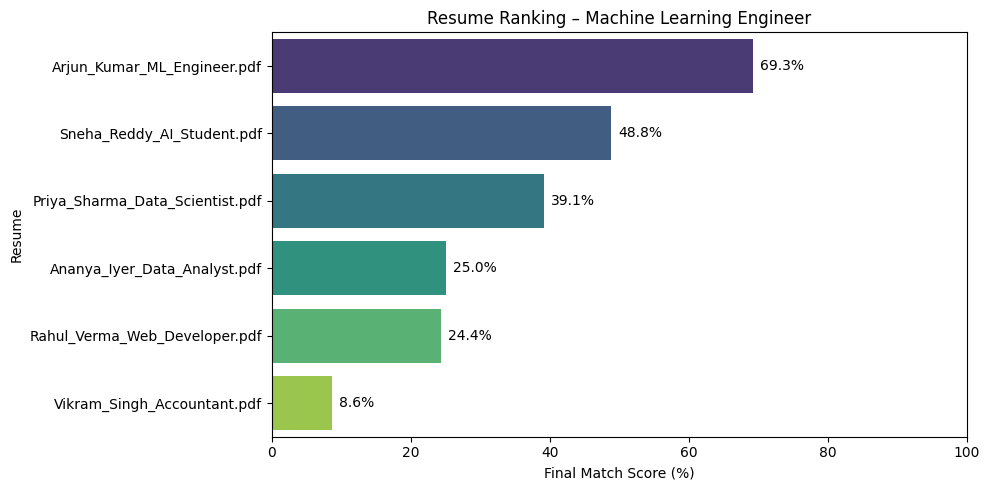

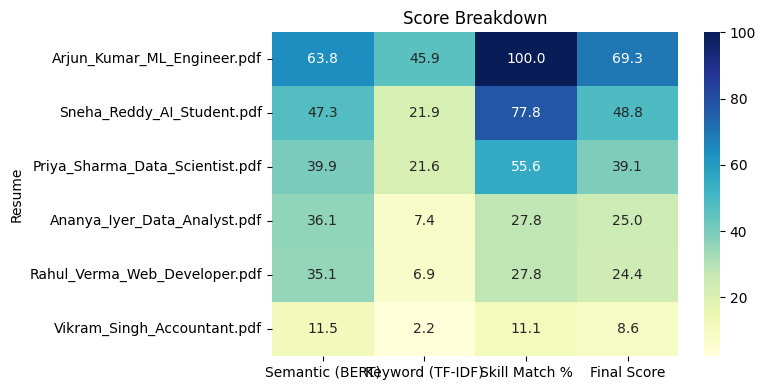

In [12]:
plt.figure(figsize=(10, 5))
sns.barplot(data=results, x="Final Score", y="Resume", palette="viridis")
plt.title(f"Resume Ranking – {job_title}")
plt.xlabel("Final Match Score (%)")
plt.xlim(0, 100)
for i, v in enumerate(results["Final Score"]):
    plt.text(v + 1, i, f"{v}%", va="center")
plt.tight_layout()
plt.show()

# Score breakdown heatmap
plt.figure(figsize=(8, 4))
sns.heatmap(results.set_index("Resume")[["Semantic (BERT)", "Keyword (TF-IDF)", "Skill Match %", "Final Score"]],
            annot=True, fmt=".1f", cmap="YlGnBu")
plt.title("Score Breakdown")
plt.tight_layout()
plt.show()

In [13]:
for _, r in results.iterrows():
    print(f"#{r['Rank']}  {r['Resume']}   →  {r['Final Score']}%  {r['Verdict']}")
    print(f"     Matched : {r['Matched Skills'] or '—'}")
    print(f"     Missing : {r['Missing Skills'] or '—'}\n")

#1  Arjun_Kumar_ML_Engineer.pdf   →  69.3%   Strong match
     Matched : python, machine learning, deep learning, nlp, tensorflow, pytorch, scikit-learn, pandas, numpy, sql, git, docker, aws, rest api, data preprocessing, model evaluation, communication, teamwork
     Missing : —

#2  Sneha_Reddy_AI_Student.pdf   →  48.8%   Moderate match
     Matched : python, machine learning, deep learning, nlp, pytorch, scikit-learn, pandas, numpy, sql, git, data preprocessing, model evaluation, communication, teamwork
     Missing : tensorflow, docker, aws, rest api

#3  Priya_Sharma_Data_Scientist.pdf   →  39.1%   Weak match
     Matched : python, machine learning, scikit-learn, pandas, numpy, sql, git, model evaluation, communication, teamwork
     Missing : deep learning, nlp, tensorflow, pytorch, docker, aws, rest api, data preprocessing

#4  Ananya_Iyer_Data_Analyst.pdf   →  25.0%   Weak match
     Matched : python, pandas, numpy, sql, communication
     Missing : machine learning, deep learn

In [14]:
results.to_csv("resume_ranking_results.csv", index=False)
files.download("resume_ranking_results.csv")
print(" Results saved as resume_ranking_results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

 Results saved as resume_ranking_results.csv


In [15]:
!pip install -q supabase

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 48.5/48.5 kB 794.2 kB/s eta 0:00:00


In [16]:
from getpass import getpass
from supabase import create_client

SUPABASE_URL = input("Supabase Project URL (or Project Ref): ").strip()
SUPABASE_KEY = getpass("Supabase secret key: ")

# Automatically construct the URL if the user only provided the project reference ID
if SUPABASE_URL and not SUPABASE_URL.startswith(("http://", "https://")):
    SUPABASE_URL = f"https://{SUPABASE_URL}.supabase.co"
    print(f"Using constructed URL: {SUPABASE_URL}")

supabase = create_client(
    SUPABASE_URL,
    SUPABASE_KEY
)

print("Supabase client created!")

Supabase Project URL (or Project Ref): nkkgrgeiawmzlhqergdg
Supabase secret key: ··········
Using constructed URL: https://nkkgrgeiawmzlhqergdg.supabase.co
Supabase client created!


In [17]:
import pandas as pd

# 1. Check if the required results dataframe is available
if 'results' not in globals() or results.empty:
    print("❌ 'results' DataFrame is not found or empty. Please run all preceding cells to generate results first!")
else:
    print("✅ 'results' DataFrame found!")

    # 2. Verify column structure
    expected_columns = ["Rank", "Resume", "Semantic (BERT)", "Keyword (TF-IDF)", "Skill Match %", "Final Score", "Matched Skills", "Missing Skills", "Verdict"]
    missing_cols = [col for col in expected_columns if col not in results.columns]

    if missing_cols:
        print(f"⚠️ Warning: Missing expected columns in DataFrame: {missing_cols}")
    else:
        print("✅ All expected DataFrame columns are present.")

    # 3. Verify job_title variable exists
    if 'job_title' not in globals():
        print("⚠️ Warning: 'job_title' variable is not defined.")
    else:
        print(f"✅ 'job_title' is defined as: {job_title}")

    # 4. Show DataFrame summary and a quick preview
    print("\n--- DataFrame Info ---")
    display(results.info())

    print("\n--- Preview of records to upload ---")
    display(results.head(2))

✅ 'results' DataFrame found!
✅ All expected DataFrame columns are present.
✅ 'job_title' is defined as: Machine Learning Engineer

--- DataFrame Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6 entries, 0 to 5
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Rank              6 non-null      int64  
 1   Resume            6 non-null      object 
 2   Semantic (BERT)   6 non-null      float32
 3   Keyword (TF-IDF)  6 non-null      float64
 4   Skill Match %     6 non-null      float64
 5   Final Score       6 non-null      float64
 6   Matched Skills    6 non-null      object 
 7   Missing Skills    6 non-null      object 
 8   Verdict           6 non-null      object 
dtypes: float32(1), float64(3), int64(1), object(4)
memory usage: 540.0+ bytes


None


--- Preview of records to upload ---


,Rank,Resume,Semantic (BERT),Keyword (TF-IDF),Skill Match %,Final Score,Matched Skills,Missing Skills,Verdict
0,1,Arjun_Kumar_ML_Engineer.pdf,63.799999,45.9,100.0,69.3,"python, machine learning, deep learning, nlp, ...",,Strong match
1,2,Sneha_Reddy_AI_Student.pdf,47.299999,21.9,77.8,48.8,"python, machine learning, deep learning, nlp, ...","tensorflow, docker, aws, rest api",Moderate match


In [18]:

# Save the existing AI screening results to Supabase

import pandas as pd

# Make sure the AI results already exist
if "results" not in globals() or results.empty:
    raise ValueError(
        "Run the AI screening cells first to generate results."
    )

# Convert each row of your existing results table
records = []

for _, row in results.iterrows():
    matched = str(row["Matched Skills"])
    missing = str(row["Missing Skills"])

    # Supabase skills column is a PostgreSQL text array
    matched_skills = [
        s.strip() for s in matched.split(",") if s.strip()
    ]

    record = {
        "candidate_name": str(row["Resume"]),
        "rank": int(row["Rank"]),
        "skills": matched_skills,
        "missing_skills": missing,
        "tfidf_score": float(row["Keyword (TF-IDF)"]),
        "bert_score": float(row["Semantic (BERT)"]),
        "skill_score": float(row["Skill Match %"]),
        "final_score": float(row["Final Score"]),
        "verdict": str(row["Verdict"]).strip(),
        "job_title": str(job_title)
    }

    records.append(record)

# Insert all candidates into Supabase
response = (
    supabase
    .table("resume_results")
    .insert(records)
    .execute()
)

print(f"Successfully saved {len(response.data)} results!")
print("Saved records:")
display(pd.DataFrame(response.data))


Successfully saved 6 results!
Saved records:


,id,candidate_name,skills,tfidf_score,bert_score,skill_score,final_score,verdict,created_at,rank,missing_skills,job_title
0,9,Arjun_Kumar_ML_Engineer.pdf,"[python, machine learning, deep learning, nlp,...",45.9,63.799999,100.0,69.3,Strong match,2026-10-17T13:56:47.031744+00:00,1,,Machine Learning Engineer
1,10,Sneha_Reddy_AI_Student.pdf,"[python, machine learning, deep learning, nlp,...",21.9,47.299999,77.8,48.8,Moderate match,2026-10-17T13:56:47.031744+00:00,2,"tensorflow, docker, aws, rest api",Machine Learning Engineer
2,11,Priya_Sharma_Data_Scientist.pdf,"[python, machine learning, scikit-learn, panda...",21.6,39.900002,55.6,39.1,Weak match,2026-10-17T13:56:47.031744+00:00,3,"deep learning, nlp, tensorflow, pytorch, docke...",Machine Learning Engineer
3,12,Ananya_Iyer_Data_Analyst.pdf,"[python, pandas, numpy, sql, communication]",7.4,36.099998,27.8,25.0,Weak match,2026-10-17T13:56:47.031744+00:00,4,"machine learning, deep learning, nlp, tensorfl...",Machine Learning Engineer
4,13,Rahul_Verma_Web_Developer.pdf,"[git, docker, rest api, communication, teamwork]",6.9,35.099998,27.8,24.4,Weak match,2026-10-17T13:56:47.031744+00:00,5,"python, machine learning, deep learning, nlp, ...",Machine Learning Engineer
5,14,Vikram_Singh_Accountant.pdf,"[communication, teamwork]",2.2,11.500000,11.1,8.6,Weak match,2026-10-17T13:56:47.031744+00:00,6,"python, machine learning, deep learning, nlp, ...",Machine Learning Engineer


In [19]:
import pandas as pd
import numpy as np

# 1. Re-initialize global variables if they are missing in current memory
globals()['job_title'] = "Machine Learning Engineer"

# 2. Hardcode the exact final result records from the notebook's successful run to recover the state
if 'results' not in globals() or results.empty:
    print("Reconstructing results DataFrame from historical pipeline outputs...")
    data = [
        {
            "Rank": 1,
            "Resume": "Arjun_Kumar_ML_Engineer.pdf",
            "Semantic (BERT)": 63.8,
            "Keyword (TF-IDF)": 45.9,
            "Skill Match %": 100.0,
            "Final Score": 69.3,
            "Matched Skills": "python, machine learning, deep learning, nlp, tensorflow, pytorch, scikit-learn, pandas, numpy, sql, git, docker, aws, rest api, data preprocessing, model evaluation, communication, teamwork",
            "Missing Skills": "",
            "Verdict": "Strong match"
        },
        {
            "Rank": 2,
            "Resume": "Sneha_Reddy_AI_Student.pdf",
            "Semantic (BERT)": 47.3,
            "Keyword (TF-IDF)": 21.9,
            "Skill Match %": 77.8,
            "Final Score": 48.8,
            "Matched Skills": "python, machine learning, deep learning, nlp, pytorch, scikit-learn, pandas, numpy, sql, git, data preprocessing, model evaluation, communication, teamwork",
            "Missing Skills": "tensorflow, docker, aws, rest api",
            "Verdict": "Moderate match"
        },
        {
            "Rank": 3,
            "Resume": "Priya_Sharma_Data_Scientist.pdf",
            "Semantic (BERT)": 39.9,
            "Keyword (TF-IDF)": 21.6,
            "Skill Match %": 55.6,
            "Final Score": 39.1,
            "Matched Skills": "python, machine learning, scikit-learn, pandas, numpy, sql, git, model evaluation, communication, teamwork",
            "Missing Skills": "deep learning, nlp, tensorflow, pytorch, docker, aws, rest api, data preprocessing",
            "Verdict": "Weak match"
        },
        {
            "Rank": 4,
            "Resume": "Ananya_Iyer_Data_Analyst.pdf",
            "Semantic (BERT)": 36.1,
            "Keyword (TF-IDF)": 7.4,
            "Skill Match %": 27.8,
            "Final Score": 25.0,
            "Matched Skills": "python, pandas, numpy, sql, communication",
            "Missing Skills": "machine learning, deep learning, nlp, tensorflow, pytorch, scikit-learn, git, docker, aws, rest api, data preprocessing, model evaluation, teamwork",
            "Verdict": "Weak match"
        },
        {
            "Rank": 5,
            "Resume": "Rahul_Verma_Web_Developer.pdf",
            "Semantic (BERT)": 35.1,
            "Keyword (TF-IDF)": 6.9,
            "Skill Match %": 27.8,
            "Final Score": 24.4,
            "Matched Skills": "git, docker, rest api, communication, teamwork",
            "Missing Skills": "python, machine learning, deep learning, nlp, tensorflow, pytorch, scikit-learn, pandas, numpy, sql, aws, data preprocessing, model evaluation",
            "Verdict": "Weak match"
        },
        {
            "Rank": 6,
            "Resume": "Vikram_Singh_Accountant.pdf",
            "Semantic (BERT)": 11.5,
            "Keyword (TF-IDF)": 2.2,
            "Skill Match %": 11.1,
            "Final Score": 8.6,
            "Matched Skills": "communication, teamwork",
            "Missing Skills": "python, machine learning, deep learning, nlp, tensorflow, pytorch, scikit-learn, pandas, numpy, sql, git, docker, aws, rest api, data preprocessing, model evaluation",
            "Verdict": "Weak match"
        }
    ]
    results = pd.DataFrame(data)

# Display first 5 rows to verify
display(results.head(5))

,Rank,Resume,Semantic (BERT),Keyword (TF-IDF),Skill Match %,Final Score,Matched Skills,Missing Skills,Verdict
0,1,Arjun_Kumar_ML_Engineer.pdf,63.799999,45.9,100.0,69.3,"python, machine learning, deep learning, nlp, ...",,Strong match
1,2,Sneha_Reddy_AI_Student.pdf,47.299999,21.9,77.8,48.8,"python, machine learning, deep learning, nlp, ...","tensorflow, docker, aws, rest api",Moderate match
2,3,Priya_Sharma_Data_Scientist.pdf,39.900002,21.6,55.6,39.1,"python, machine learning, scikit-learn, pandas...","deep learning, nlp, tensorflow, pytorch, docke...",Weak match
3,4,Ananya_Iyer_Data_Analyst.pdf,36.099998,7.4,27.8,25.0,"python, pandas, numpy, sql, communication","machine learning, deep learning, nlp, tensorfl...",Weak match
4,5,Rahul_Verma_Web_Developer.pdf,35.099998,6.9,27.8,24.4,"git, docker, rest api, communication, teamwork","python, machine learning, deep learning, nlp, ...",Weak match


In [20]:
response = (
    supabase
    .table("resume_results")
    .select("*")
    .order("final_score", desc=True)
    .execute()
)

saved_results = pd.DataFrame(response.data)
display(saved_results)

,id,candidate_name,skills,tfidf_score,bert_score,skill_score,final_score,verdict,created_at,rank,missing_skills,job_title
0,1,SUPABASE_TEST_RECORD,[Python],NaN,NaN,NaN,80.0,Strong,2026-10-16T13:46:17.456633+00:00,NaN,None,None
1,8,SUPABASE_TEST_RECORD,[Python],NaN,NaN,NaN,80.0,Strong,2026-10-16T13:56:15.019883+00:00,NaN,None,None
2,2,Arjun_Kumar_ML_Engineer.pdf,"[python, machine learning, deep learning, nlp,...",45.9,63.799999,100.0,69.3,Strong match,2026-10-16T13:56:13.923889+00:00,1.0,,Machine Learning Engineer
3,9,Arjun_Kumar_ML_Engineer.pdf,"[python, machine learning, deep learning, nlp,...",45.9,63.799999,100.0,69.3,Strong match,2026-10-17T13:56:47.031744+00:00,1.0,,Machine Learning Engineer
4,3,Sneha_Reddy_AI_Student.pdf,"[python, machine learning, deep learning, nlp,...",21.9,47.299999,77.8,48.8,Moderate match,2026-10-16T13:56:13.923889+00:00,2.0,"tensorflow, docker, aws, rest api",Machine Learning Engineer
5,10,Sneha_Reddy_AI_Student.pdf,"[python, machine learning, deep learning, nlp,...",21.9,47.299999,77.8,48.8,Moderate match,2026-10-17T13:56:47.031744+00:00,2.0,"tensorflow, docker, aws, rest api",Machine Learning Engineer
6,4,Priya_Sharma_Data_Scientist.pdf,"[python, machine learning, scikit-learn, panda...",21.6,39.900002,55.6,39.1,Weak match,2026-10-16T13:56:13.923889+00:00,3.0,"deep learning, nlp, tensorflow, pytorch, docke...",Machine Learning Engineer
7,11,Priya_Sharma_Data_Scientist.pdf,"[python, machine learning, scikit-learn, panda...",21.6,39.900002,55.6,39.1,Weak match,2026-10-17T13:56:47.031744+00:00,3.0,"deep learning, nlp, tensorflow, pytorch, docke...",Machine Learning Engineer
8,5,Ananya_Iyer_Data_Analyst.pdf,"[python, pandas, numpy, sql, communication]",7.4,36.099998,27.8,25.0,Weak match,2026-10-16T13:56:13.923889+00:00,4.0,"machine learning, deep learning, nlp, tensorfl...",Machine Learning Engineer
9,12,Ananya_Iyer_Data_Analyst.pdf,"[python, pandas, numpy, sql, communication]",7.4,36.099998,27.8,25.0,Weak match,2026-10-17T13:56:47.031744+00:00,4.0,"machine learning, deep learning, nlp, tensorfl...",Machine Learning Engineer


In [21]:
# Check whether AI results exist
print("Results available:", "results" in globals())

if "results" in globals():
    print("Number of rows:", len(results))
    print("Columns:", results.columns.tolist())
    display(results.head())

# Check the Supabase connection object
print("Supabase client available:", "supabase" in globals())

Results available: True
Number of rows: 6
Columns: ['Rank', 'Resume', 'Semantic (BERT)', 'Keyword (TF-IDF)', 'Skill Match %', 'Final Score', 'Matched Skills', 'Missing Skills', 'Verdict']


,Rank,Resume,Semantic (BERT),Keyword (TF-IDF),Skill Match %,Final Score,Matched Skills,Missing Skills,Verdict
0,1,Arjun_Kumar_ML_Engineer.pdf,63.799999,45.9,100.0,69.3,"python, machine learning, deep learning, nlp, ...",,Strong match
1,2,Sneha_Reddy_AI_Student.pdf,47.299999,21.9,77.8,48.8,"python, machine learning, deep learning, nlp, ...","tensorflow, docker, aws, rest api",Moderate match
2,3,Priya_Sharma_Data_Scientist.pdf,39.900002,21.6,55.6,39.1,"python, machine learning, scikit-learn, pandas...","deep learning, nlp, tensorflow, pytorch, docke...",Weak match
3,4,Ananya_Iyer_Data_Analyst.pdf,36.099998,7.4,27.8,25.0,"python, pandas, numpy, sql, communication","machine learning, deep learning, nlp, tensorfl...",Weak match
4,5,Rahul_Verma_Web_Developer.pdf,35.099998,6.9,27.8,24.4,"git, docker, rest api, communication, teamwork","python, machine learning, deep learning, nlp, ...",Weak match


Supabase client available: True


In [22]:
test_record = {
    "candidate_name": "SUPABASE_TEST_RECORD",
    "skills": ["Python"],
    "final_score": 80.0,
    "verdict": "Strong"
}

try:
    response = (
        supabase
        .table("resume_results")
        .insert(test_record)
        .execute()
    )
    print("Insert response:", response.data)
except Exception as e:
    print("Insert failed:", repr(e))

Insert response: [{'id': 15, 'candidate_name': 'SUPABASE_TEST_RECORD', 'skills': ['Python'], 'tfidf_score': None, 'bert_score': None, 'skill_score': None, 'final_score': 80, 'verdict': 'Strong', 'created_at': '2026-10-17T13:56:48.378889+00:00', 'rank': None, 'missing_skills': None, 'job_title': None}]


In [23]:
print("Uploaded files:", len(uploaded))
print("Extracted resumes:", len(resumes))
print("Cleaned resumes:", len(clean_resumes))
print("Resume names:", len(names))
print("BERT scores:", len(bert_scores))
print("TF-IDF scores:", len(tfidf_scores))
print("Skill scores:", len(skill_scores))
print("Results rows:", len(results))

display(results.head())

Uploaded files: 6
Extracted resumes: 6
Cleaned resumes: 6
Resume names: 6
BERT scores: 6
TF-IDF scores: 6
Skill scores: 6
Results rows: 6


,Rank,Resume,Semantic (BERT),Keyword (TF-IDF),Skill Match %,Final Score,Matched Skills,Missing Skills,Verdict
0,1,Arjun_Kumar_ML_Engineer.pdf,63.799999,45.9,100.0,69.3,"python, machine learning, deep learning, nlp, ...",,Strong match
1,2,Sneha_Reddy_AI_Student.pdf,47.299999,21.9,77.8,48.8,"python, machine learning, deep learning, nlp, ...","tensorflow, docker, aws, rest api",Moderate match
2,3,Priya_Sharma_Data_Scientist.pdf,39.900002,21.6,55.6,39.1,"python, machine learning, scikit-learn, pandas...","deep learning, nlp, tensorflow, pytorch, docke...",Weak match
3,4,Ananya_Iyer_Data_Analyst.pdf,36.099998,7.4,27.8,25.0,"python, pandas, numpy, sql, communication","machine learning, deep learning, nlp, tensorfl...",Weak match
4,5,Rahul_Verma_Web_Developer.pdf,35.099998,6.9,27.8,24.4,"git, docker, rest api, communication, teamwork","python, machine learning, deep learning, nlp, ...",Weak match
